# Assignment 2 Continuous-time Fourier series and transform

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Uppgift 1a

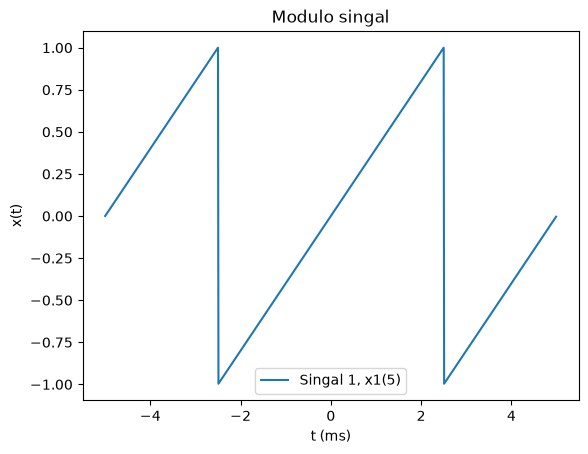

In [2]:
import numpy as np
import matplotlib.pyplot as plt

dt = 0.00001
t1 = np.arange(-0.005, 0.005, dt)

def x1(t):
    return -1 + (1/0.0025) * np.mod(t - 0.0025, 0.005)

plt.plot(t1 * 1000, x1(t1), label="Singal 1, x1(5)")
plt.title("Modulo singal")
plt.xlabel("t (ms)")
plt.ylabel("x(t)")
plt.legend()
plt.show()

# Uppgift 1b

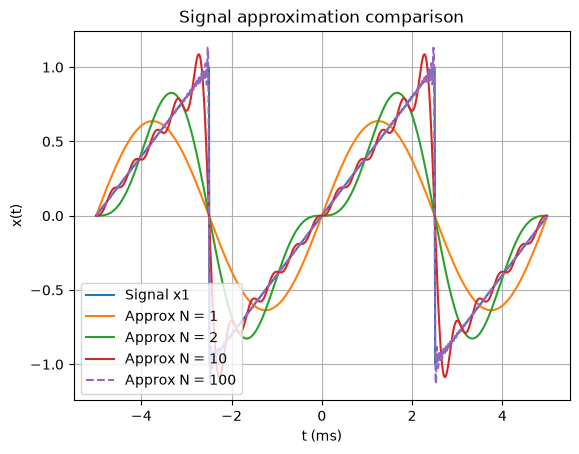

In [3]:
N = np.array([1, 2, 10, 100])
T0 = 0.005 # 5 ms

def x_fourier(t, N_val):
    omega = 2 * np.pi / T0
    n = np.arange(-N_val, N_val + 1, 1)

    c = np.zeros(n.shape, dtype=complex)
    mask = (n != 0)
    c[mask] = ((-1.0)**n[mask]) * 1j * 1 / (n[mask] * np.pi)
        
    terms = c[:, None] * np.exp(1j * n[:, None] * omega * t[None, :]) # broadcast
    
    return np.real(np.sum(terms, axis=0))
    
approx1 = x_fourier(t1, N[0])
approx2 = x_fourier(t1, N[1])
approx3 = x_fourier(t1, N[2])
approx4 = x_fourier(t1, N[3])

fig, ax = plt.subplots()
ax.plot(t1*1000, x1(t1), label="Signal x1")
ax.plot(t1*1000, approx1, label="Approx N = 1")
ax.plot(t1*1000, approx2, label="Approx N = 2")
ax.plot(t1*1000, approx3, label="Approx N = 10")
ax.plot(t1*1000, approx4, label="Approx N = 100", linestyle="--")

ax.set_title("Signal approximation comparison")
ax.set_xlabel("t (ms)")
ax.set_ylabel("x(t)")
ax.legend()
ax.grid(True)
plt.show()

# Uppgift 1c

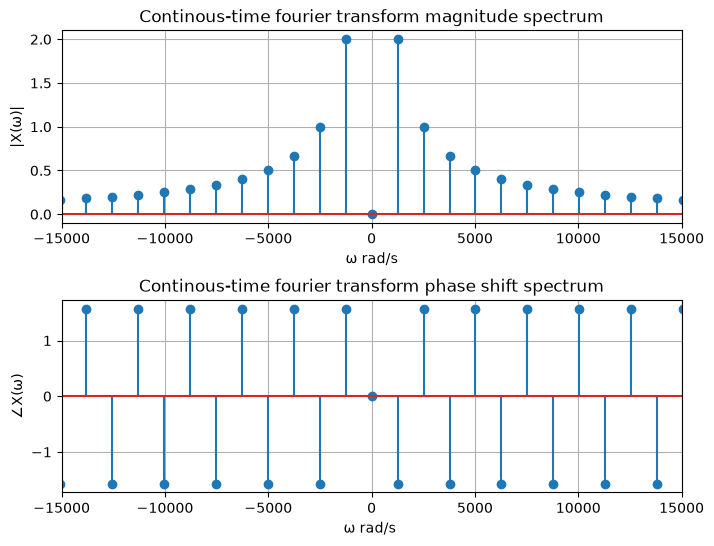

In [4]:
def X(n):
    c = np.zeros(n.shape, dtype=complex)
    mask = (n != 0)
    c[mask] = ((-1.0)**n[mask]) * 1j * 1 / (n[mask] * np.pi)

    return 2*np.pi*c

w0 = 2 * np.pi / T0
M = 100
n = np.arange(-M, +M+1, 1)
wn = n * w0

Xn = X(n)

fig, ax = plt.subplots(2, 1, figsize=(8, 6))
ax[0].stem(wn, np.abs(Xn))
ax[1].stem(wn, np.angle(Xn))

ax[0].set_xlabel(" ω rad/s ")
ax[0].set_ylabel("|X(ω)|")
ax[0].set_xlim(-15e3, 15e3)

ax[1].set_xlabel(" ω rad/s  ")
ax[1].set_ylabel("∠X(ω)")
ax[1].set_xlim(-15e3, 15e3)

ax[0].set_title("Continous-time fourier transform magnitude spectrum")
ax[1].set_title("Continous-time fourier transform phase shift spectrum")

ax[0].grid()
ax[1].grid()

plt.subplots_adjust(hspace=0.4)  # Ökar det vertikala avståndet mellan subplots

plt.show()

# Uppgift 2

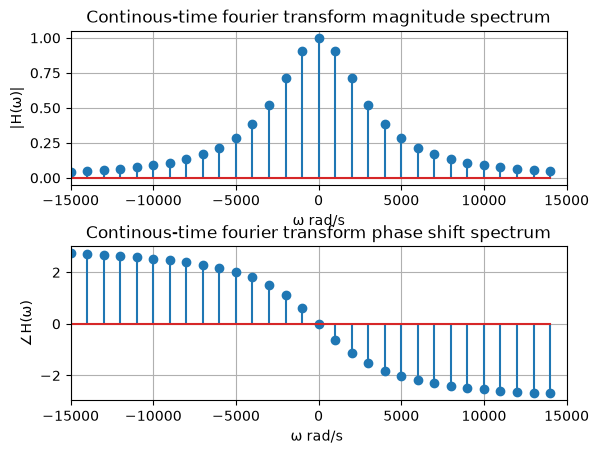

In [5]:
alfa = 1000 * np.pi

def u(t):
    return np.where(t >= 0, 1, 0)

def h(t):
    return alfa**2*t*np.exp(-alfa*t)*u(t)

def freq_resp(w):
    return (alfa / (alfa + 1j * w)) **2

dw = 1000
w = np.arange(-15e3, 15e3, dw)

Hn = freq_resp(w)

fig, ax = plt.subplots(2, 1)
ax[0].stem(w, np.abs(Hn))
ax[1].stem(w, np.angle(Hn))

ax[0].set_xlabel(" ω rad/s ")
ax[0].set_ylabel("|H(ω)|")
ax[0].set_xlim(-15e3, 15e3)


ax[1].set_xlabel(" ω rad/s  ")
ax[1].set_ylabel("∠H(ω)")
ax[1].set_xlim(-15e3, 15e3)


ax[0].set_title("Continous-time fourier transform magnitude spectrum")
ax[1].set_title("Continous-time fourier transform phase shift spectrum")

ax[0].grid()
ax[1].grid()

plt.subplots_adjust(hspace=0.4)  # Ökar det vertikala avståndet mellan subplots

plt.show()

# Uppgift 3a

(201,)


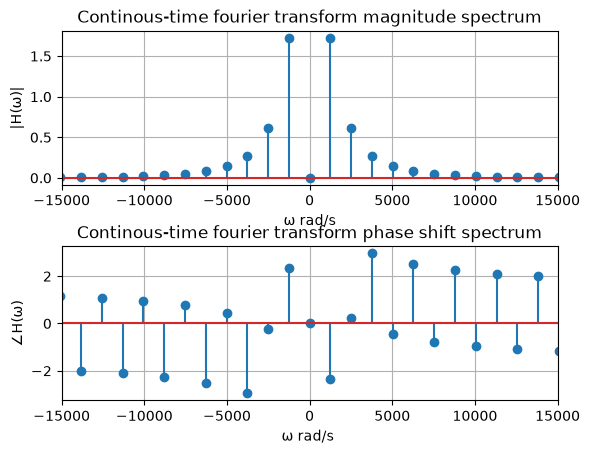

In [6]:
Hn_wn = freq_resp(wn)
Yn = Hn_wn * Xn
print(Yn.shape)

# print(Yn.shape)

fig, ax = plt.subplots(2, 1)

ax[0].stem(wn, np.abs(Yn))
ax[1].stem(wn, np.angle(Yn))

ax[0].set_xlabel(" ω rad/s ")
ax[0].set_ylabel("|H(ω)|")
ax[0].set_xlim(-15e3, 15e3)


ax[1].set_xlabel(" ω rad/s  ")
ax[1].set_ylabel("∠H(ω)")
ax[1].set_xlim(-15e3, 15e3)


ax[0].set_title("Continous-time fourier transform magnitude spectrum")
ax[1].set_title("Continous-time fourier transform phase shift spectrum")

ax[0].grid()
ax[1].grid()

plt.subplots_adjust(hspace=0.4)  # Ökar det vertikala avståndet mellan subplots

plt.show()

# Uppgift 3b

(3,)
(201,)
(1000,)
(5,)
(201,)
(1000,)
(21,)
(201,)
(1000,)
(201,)
(201,)
(1000,)


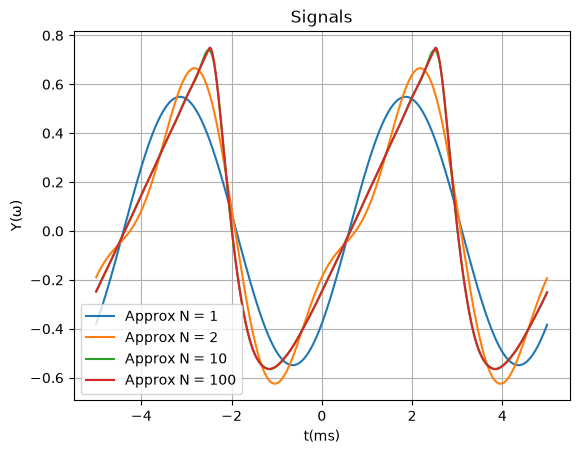

In [ ]:
def output(t, N_val):
    omega = 2 * np.pi / T0
    n1 = np.arange(-N_val, N_val + 1, 1)

    indices = n1 + M
    Yn_subset = Yn[indices]

    exponent = (1j * n1[:, None] * omega * t[None, :])
    terms = Yn_subset[:, None] * np.exp(exponent)
    y = np.sum(terms, axis=0)
    return 1/(2 * np.pi) * np.real(y)

N = np.array([1, 2, 10, 100])

o_approx1 = output(t1, N[0])
o_approx2 = output(t1, N[1])
o_approx3 = output(t1, N[2])
o_approx4 = output(t1, N[3])

fig, ax = plt.subplots()

ax.plot(t1*1000,o_approx1, label="Approx N = 1")
ax.plot(t1*1000, o_approx2, label="Approx N = 2")
ax.plot(t1*1000, o_approx3, label="Approx N = 10")
ax.plot(t1*1000, o_approx4, label="Approx N = 100")

ax.set_title("Signals")
ax.set_xlabel("t(ms)")
ax.set_ylabel("Y(ω)")
ax.legend()
ax.grid(True)

plt.show()
